# H8 · "Computers are complements for humans, not substitutes" (*Zero to One*, ch. 12)

Thiel argues that fears of technological unemployment are misplaced. Computers and people are good at different things, so computers make people more productive rather than replacing them; the most valuable companies will "empower people rather than make them obsolete". Globalisation, not technology, is what pits workers against substitutes.

| Claim | Test | Data |
|---|---|---|
| **H8a.** Computers raise output per worker without destroying jobs. | Labour productivity, real median earnings, the labour share and the prime-age employment rate, 1979 to the latest year, by period (including 2014 onward). | FRED: `OPHNFB`, `LES1252881600Q`, `PRS85006173`, `LNS12300060`, `UNRATE` |
| **H8b.** Jobs that use computers most should grow, not shrink. | Employment and real wage growth, 2014 to the latest year, across about 750 occupations ranked by how important computers are to the job. Contrast: jobs that are themselves automated or repetitive (the classic "substitute" jobs). | BLS Occupational Employment and Wage Statistics (OEWS); O\*NET 'Working with Computers', 'Degree of Automation', 'Repeating Same Tasks' |
| **H8c.** Does the AI wave since 2022 change the picture? | Employment and wage growth before (2014–2022) and after (2022–latest) ChatGPT, by occupations' exposure to AI. If AI substitutes, exposed jobs should slow after 2022. | Felten, Raj and Seamans (2021) AI Occupational Exposure (AIOE) |

**Caveats**
* Occupation codes changed in 2018. Occupations are merged into stable groups using the BLS crosswalk, so a few groups combine several jobs.
* The O\*NET scores describe jobs today; jobs that already lost most workers to computers before 2014 are not visible.
* Employment growth reflects demand, trade and demographics as well as technology. These are associations.

**Before running:** the notebook installs `openpyxl` if it is missing (needed to read the BLS spreadsheets). Downloads go to `data/raw/oews`, `data/raw/onet` and `data/raw/aioe` (about 15 MB). BLS asks scripts to identify themselves; the notebook uses the contact in `SEC_USER_AGENT` from your `.env`. If a BLS download is refused, the message gives the link to save by hand.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import importlib.util, subprocess, sys
if importlib.util.find_spec("openpyxl") is None:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "openpyxl"])
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
import sys; from pathlib import Path  # thiel_common.py lives in the repo root
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "thiel_common.py").exists())))
import thiel_common as tc
tc.style()
print("synthetic mode" if tc.SYNTHETIC else "live data")


def annual(sid):
    # Annual average over complete years only
    s = tc.fred(sid).dropna()
    c = s.groupby(s.index.year).count()
    return s.groupby(s.index.year).mean()[c == c.max()]

live data


## H8a · Productivity, pay and jobs since 1979

In [2]:
prod, earn, share = annual("OPHNFB"), annual("LES1252881600Q"), annual("PRS85006173")
epop, unemp = annual("LNS12300060"), annual("UNRATE")
LAST = int(min(prod.index.max(), earn.index.max(), epop.index.max()))
periods = [(1979, 1995), (1995, 2004), (2004, 2014), (2014, LAST)]
gr = lambda s, a, b: 100 * np.log(s.loc[b] / s.loc[a]) / (b - a)
agg = pd.DataFrame({f"{a}-{b}": {
    "Labour productivity, % per year": gr(prod, a, b),
    "Real median weekly earnings, % per year": gr(earn, a, b),
    "Labour share, change in points": share.loc[b] - share.loc[a] if a in share.index and b in share.index else np.nan,
    "Prime-age employment rate at end, %": epop.loc[b]} for a, b in periods}).round(2)
tc.save_table(agg, "h8a_aggregate_periods")
levels = pd.DataFrame({"prime_age_employment_rate": epop, "unemployment_rate": unemp}).loc[[2000, 2007, 2014, 2019, LAST]].round(1)
print(levels.to_string()); agg

      prime_age_employment_rate  unemployment_rate
date                                              
2000                       81.5                4.0
2007                       79.9                4.6
2014                       76.7                6.2
2019                       80.0                3.7
2024                       80.7                4.0


,1979-1995,1995-2004,2004-2014,2014-2024
"Labour productivity, % per year",1.50,3.04,1.56,1.79
"Real median weekly earnings, % per year",-0.33,0.79,-0.10,1.00
"Labour share, change in points",-3.61,-0.83,-7.68,-2.27
"Prime-age employment rate at end, %",79.74,78.97,76.70,80.72


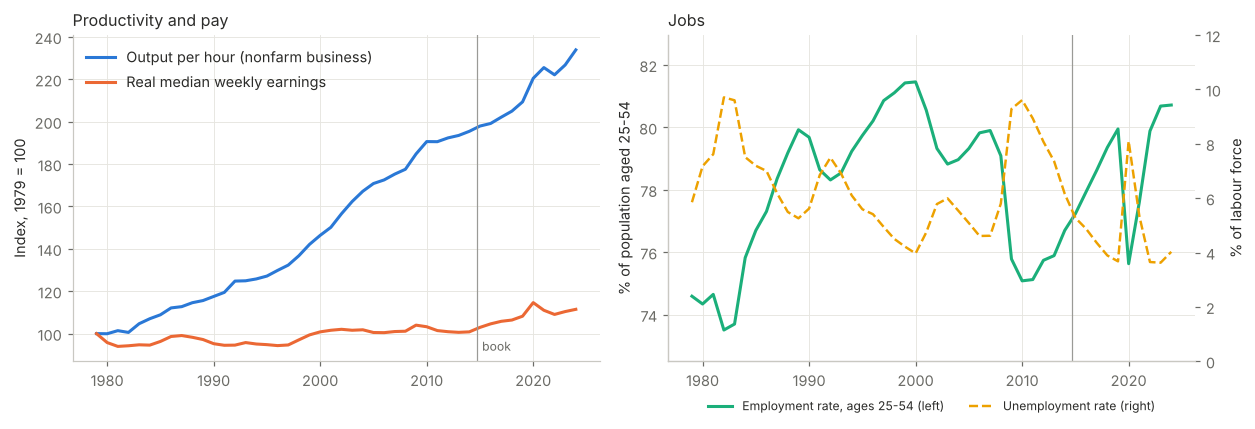

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
ax = axes[0]
for s, lab, c in [(prod, "Output per hour (nonfarm business)", tc.C[0]), (earn, "Real median weekly earnings", tc.C[1])]:
    s = s.loc[1979:LAST]; ax.plot(s.index, 100 * s / s.iloc[0], color=c, lw=2, label=lab)
ax.axvline(2014.7, color=tc.GREY, lw=0.8); ax.text(2015.2, ax.get_ylim()[0] + 5, "book", color=tc.MUTED, fontsize=8)
ax.set_ylabel("Index, 1979 = 100"); ax.set_title("Productivity and pay", loc="left"); ax.legend(loc="upper left")
ax = axes[1]
e = epop.loc[1979:LAST]; u = unemp.loc[1979:LAST]
ax.plot(e.index, e, color=tc.C[2], lw=2, label="Employment rate, ages 25-54 (left)")
ax.set_ylabel("% of population aged 25-54"); ax.set_ylim(e.min() - 1, e.max() + 1.5)
ax2 = ax.twinx(); ax2.plot(u.index, u, color=tc.C[3], lw=1.6, ls="--", label="Unemployment rate (right)")
ax2.set_ylabel("% of labour force"); ax2.set_ylim(0, 12); ax2.grid(False)
ax.axvline(2014.7, color=tc.GREY, lw=0.8)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=2, fontsize=8); ax.set_title("Jobs", loc="left")
fig.tight_layout(); tc.save_fig(fig, "h8_fig1_aggregate")

## H8b · Which occupations grew? Computer use against automation

Occupations are matched across the 2018 code change through the BLS crosswalk; codes that split or merged become one group. Each group gets O\*NET scores averaged over its current occupations, weighted by employment. Scores are standardised (mean 0, standard deviation 1, weighted by 2014 employment), so a coefficient is the change in yearly growth, in percentage points, for one standard deviation more of that trait.

In [4]:
END = tc.latest_oews_year()
o14, o22, oE = tc.oews_national(2014), tc.oews_national(2022), tc.oews_national(END)
xw = tc.soc_crosswalk()
print(f"OEWS detailed occupations: 2014 {len(o14)}, 2022 {len(o22)}, {END} {len(oE)}; crosswalk rows {len(xw)}")
g10, g18 = tc.soc_groups(o14.occ_code, pd.concat([o22.occ_code, oE.occ_code]), xw)


def to_groups(o, gmap, yr):
    o = o.assign(g=o.occ_code.map(gmap)).dropna(subset=["g", "emp"])
    o = o.assign(wx=o.wage * o.emp, ew=o.emp.where(o.wage.notna()))
    a = o.groupby("g").agg(emp=("emp", "sum"), wx=("wx", "sum"), ew=("ew", "sum"))
    a["wage"] = (a.wx / a.ew).where(a.ew > 0)
    return a[["emp", "wage"]].add_suffix(f"_{yr}")


def score(codes, weights, table):
    # Employment-weighted mean of a code-level score table; OEWS aggregates (codes ending in 0) use their detailed codes
    rows = []
    for c, w in zip(codes, weights):
        if c in table.index:
            v = table.loc[[c]].mean()
        elif c.endswith("0"):
            v = table[table.index.str[:6] == c[:6]].mean()
        else:
            continue
        rows.append(v.rename(c).to_frame().T.assign(_w=w if w > 0 else 1.0))
    return pd.concat(rows) if rows else pd.DataFrame()


onet = tc.onet_scores()
sE = score(oE.occ_code, oE.emp.fillna(0), onet).assign(g=lambda d: d.index.map(g18))
wmean = lambda d, cols: pd.Series({c: np.average(d[c].dropna(), weights=d._w[d[c].notna()]) if d[c].notna().any() else np.nan for c in cols})
onet_g = sE.groupby("g").apply(lambda d: wmean(d, ["computer", "automation", "repetitive"]))

P = to_groups(o14, g10, 2014).join(to_groups(o22, g18, 2022), how="outer").join(to_groups(oE, g18, END), how="outer").join(onet_g)
first = oE.assign(g=oE.occ_code.map(g18)).sort_values("emp", ascending=False).groupby("g")
P["title"] = first.title.first(); P["n_codes"] = first.occ_code.nunique()
P.loc[P.n_codes > 1, "title"] = P.title + " (and related)"

ai = tc.aioe_scores()
if len(ai):
    sA = score(o14.occ_code, o14.emp.fillna(0), ai.to_frame("aioe")).assign(g=lambda d: d.index.map(g10))
    P = P.join(sA.groupby("g").apply(lambda d: wmean(d, ["aioe"])))

cpi = annual("CPIAUCSL")
defl = lambda y: cpi.loc[y] if y in cpi.index else cpi.iloc[-1]
both = P[(P.emp_2014 > 0) & (P[f"emp_{END}"] > 0)].copy()
cov = {"share_2014_emp_matched": round(100 * both.emp_2014.sum() / P.emp_2014.sum(), 1),
       f"share_{END}_emp_matched": round(100 * both[f"emp_{END}"].sum() / P[f"emp_{END}"].sum(), 1),
       "groups": int(len(both)), "groups_with_onet": int(both.computer.notna().sum())}
print("Coverage:", cov)

yrs = END - 2014
both["g_emp"] = 100 * np.log(both[f"emp_{END}"] / both.emp_2014) / yrs
both["g_wage"] = 100 * (np.log(both[f"wage_{END}"] / both.wage_2014) - np.log(defl(END) / defl(2014))) / yrs


def wz(x, w):
    m = np.average(x[x.notna()], weights=w[x.notna()]); s = np.sqrt(np.average((x[x.notna()] - m) ** 2, weights=w[x.notna()]))
    return (x - m) / s


for v in ["computer", "automation", "repetitive"] + (["aioe"] if "aioe" in both else []):
    both[f"z_{v}"] = wz(both[v], both.emp_2014)
both["z_logwage"] = wz(np.log(both.wage_2014), both.emp_2014)          # starting pay level (computer-heavy jobs pay more)
both[["title", "emp_2014", f"emp_{END}", "wage_2014", f"wage_{END}", "computer", "automation", "repetitive", "g_emp", "g_wage"]].describe().round(2)

OEWS 2026: download failed (ProxyError).
OEWS 2026: could not download (HTTP no response). If this keeps happening, open
  https://www.bls.gov/oes/special-requests/oesm26nat.zip
in a browser and save the file as
  /home/claude/Thiel_Tests/data/raw/oews/oesm26nat.zip
OEWS detailed occupations: 2014 820, 2022 830, 2025 830; crosswalk rows 900


Coverage: {'share_2014_emp_matched': np.float64(97.8), 'share_2025_emp_matched': np.float64(97.5), 'groups': 772, 'groups_with_onet': 728}


,emp_2014,emp_2025,wage_2014,wage_2025,computer,automation,repetitive,g_emp,g_wage
count,772.00,772.00,768.00,768.00,728.00,728.00,728.00,772.00,768.00
mean,171186.17,196404.73,55712.85,76931.54,3.52,2.07,3.26,-0.06,0.50
std,417893.32,493975.98,31238.06,42936.72,0.96,0.52,0.65,4.01,0.94
min,560.00,220.00,19030.00,31980.00,1.04,1.04,1.42,-17.16,-2.53
25%,16372.50,14275.00,34552.50,49882.36,2.75,1.68,2.82,-1.65,-0.09
50%,42860.00,44280.00,47805.00,64940.00,3.75,2.05,3.27,0.22,0.45
75%,129172.50,149997.50,68077.50,90022.50,4.31,2.41,3.69,2.16,0.99
max,4562160.00,5455030.00,246320.00,377575.48,4.97,3.80,4.92,41.87,6.25


In [5]:
def wquint(x, w, q=5):
    # Quintiles holding equal shares of base-year employment
    o = x.sort_values().index; cw = w.loc[o].cumsum() / w.loc[o].sum()
    return pd.Series(np.minimum((cw * q).apply(np.ceil).astype(int), q), index=o).reindex(x.index)


def quint_table(d, var, base, end, label):
    d = d.dropna(subset=[var]).copy(); d["q"] = wquint(d[var], d[f"emp_{base}"])
    n = end - base
    t = d.groupby("q").apply(lambda g: pd.Series({
        f"mean_{var}": np.average(g[var], weights=g[f"emp_{base}"]), "occupations": len(g),
        f"emp_{base}_m": g[f"emp_{base}"].sum() / 1e6, f"emp_{end}_m": g[f"emp_{end}"].sum() / 1e6,
        "emp_growth_pct_yr": 100 * np.log(g[f"emp_{end}"].sum() / g[f"emp_{base}"].sum()) / n,
        "real_wage_growth_pct_yr": 100 * (np.log((g[f"wage_{end}"] * g[f"emp_{end}"]).sum() / g[f"emp_{end}"].sum()
                                           / ((g[f"wage_{base}"] * g[f"emp_{base}"]).sum() / g[f"emp_{base}"].sum()))
                                      - np.log(defl(end) / defl(base))) / n}))
    t.index = [f"Q{i} ({'least' if i == 1 else 'most' if i == 5 else ''})".replace(" ()", "") for i in t.index]
    tc.save_table(t.round(3), label)
    return t


ok = both.dropna(subset=["wage_2014", f"wage_{END}"])
q_comp = quint_table(ok, "computer", 2014, END, "h8b_quintiles_computer")
q_auto = quint_table(ok, "automation", 2014, END, "h8b_quintiles_automation")
q_rep = quint_table(ok, "repetitive", 2014, END, "h8b_quintiles_repetitive")
q_pay = quint_table(ok.assign(pay_2014_k=ok.wage_2014 / 1000), "pay_2014_k", 2014, END, "h8b_quintiles_pay")
print(f"Correlation of computer use with 2014 log pay: {np.corrcoef(ok.dropna(subset=['computer']).computer, np.log(ok.dropna(subset=['computer']).wage_2014))[0, 1]:.2f}")
print("By importance of computers:"); display(q_comp.round(2))
print("By degree of automation:"); display(q_auto.round(2))
print("By repetitiveness:"); display(q_rep.round(2))
print("By 2014 pay ($ thousands):"); display(q_pay.round(2))

Correlation of computer use with 2014 log pay: 0.53
By importance of computers:


,mean_computer,occupations,emp_2014_m,emp_2025_m,emp_growth_pct_yr,real_wage_growth_pct_yr
Q1 (least),2.15,162.0,25.71,27.94,0.76,1.27
Q2,2.93,101.0,25.66,30.22,1.49,1.28
Q3,3.68,197.0,25.94,28.28,0.79,0.72
Q4,4.26,133.0,26.02,28.73,0.90,1.01
Q5 (most),4.59,132.0,25.96,33.15,2.22,0.71


By degree of automation:


,mean_automation,occupations,emp_2014_m,emp_2025_m,emp_growth_pct_yr,real_wage_growth_pct_yr
Q1 (least),1.55,230.0,25.23,28.47,1.10,0.62
Q2,1.90,136.0,25.98,31.91,1.87,0.76
Q3,2.12,100.0,26.31,27.94,0.55,1.07
Q4,2.34,104.0,25.78,31.06,1.70,0.95
Q5 (most),2.74,155.0,25.99,28.94,0.98,1.44


By repetitiveness:


,mean_repetitive,occupations,emp_2014_m,emp_2025_m,emp_growth_pct_yr,real_wage_growth_pct_yr
Q1 (least),2.57,220.0,25.59,29.47,1.28,0.66
Q2,3.11,140.0,26.03,35.11,2.72,0.83
Q3,3.39,105.0,25.71,29.03,1.11,1.29
Q4,3.66,141.0,25.85,28.91,1.02,0.91
Q5 (most),4.29,119.0,26.11,25.80,-0.11,1.01


By 2014 pay ($ thousands):


,mean_pay_2014_k,occupations,emp_2014_m,emp_2025_m,emp_growth_pct_yr,real_wage_growth_pct_yr
Q1 (least),21.97,52.0,26.07,30.14,1.32,2.00
Q2,28.41,103.0,26.55,26.24,-0.11,1.21
Q3,37.42,179.0,26.59,27.76,0.39,0.57
Q4,54.75,229.0,25.81,29.80,1.31,0.10
Q5 (most),93.92,205.0,27.01,37.56,3.00,0.16


In [6]:
reg = ok.dropna(subset=["z_computer", "z_automation", "z_repetitive", "z_logwage"])
R = []
for y in ["g_emp", "g_wage"]:
    for spec in (["z_computer"], ["z_computer", "z_automation", "z_repetitive"], ["z_computer", "z_automation", "z_repetitive", "z_logwage"]):
        r = tc.wls(reg[y], reg[spec].values, reg.emp_2014, spec).assign(y=y, spec=" + ".join(spec))
        R.append(r[r.x != "const"])
R = pd.concat(R, ignore_index=True)
tc.save_table(R, "h8b_regressions", index=False)
R.round(3)

,x,coef,se,p,n,r2,y,spec
0,z_computer,0.110,0.219,0.615,725,0.002,g_emp,z_computer
1,z_computer,0.381,0.236,0.108,725,0.061,g_emp,z_computer + z_automation + z_repetitive
2,z_automation,-0.113,0.175,0.517,725,0.061,g_emp,z_computer + z_automation + z_repetitive
3,z_repetitive,-0.692,0.222,0.002,725,0.061,g_emp,z_computer + z_automation + z_repetitive
4,z_computer,-0.376,0.183,0.040,725,0.133,g_emp,z_computer + z_automation + z_repetitive + z_l...
5,z_automation,-0.119,0.151,0.434,725,0.133,g_emp,z_computer + z_automation + z_repetitive + z_l...
6,z_repetitive,-0.327,0.176,0.063,725,0.133,g_emp,z_computer + z_automation + z_repetitive + z_l...
7,z_logwage,1.037,0.236,0.000,725,0.133,g_emp,z_computer + z_automation + z_repetitive + z_l...
8,z_computer,-0.524,0.059,0.000,725,0.318,g_wage,z_computer
9,z_computer,-0.580,0.063,0.000,725,0.342,g_wage,z_computer + z_automation + z_repetitive


In [7]:
big = ok[ok.emp_2014 >= 100_000].sort_values("g_emp")
cols = ["title", "emp_2014", f"emp_{END}", "g_emp", "g_wage", "computer", "automation", "repetitive"]
movers = pd.concat([big.head(12).assign(list="fastest decline"), big.tail(12).iloc[::-1].assign(list="fastest growth")])[cols + ["list"]]
tc.save_table(movers.round(2), "h8b_movers", index=False)
print(f"Occupations with 100,000+ workers in 2014: {len(big)}")
movers.round(2)

Occupations with 100,000+ workers in 2014: 238


,title,emp_2014,emp_2025,g_emp,g_wage,computer,automation,repetitive,list
g,,,,,,,,,
B41-9041,Telemarketers,234520.0,58430.0,-12.63,0.81,3.61,3.09,4.17,fastest decline
B15-1251,Computer Programmers,302150.0,92230.0,-10.79,-0.37,4.95,2.29,3.15,fastest decline
B43-2011,"Switchboard Operators, Including Answering Ser...",108890.0,34280.0,-10.51,1.19,3.79,2.31,3.58,fastest decline
B51-9198,Helpers--Production Workers,420520.0,165700.0,-8.47,1.75,2.62,2.62,3.21,fastest decline
B43-4151,Order Clerks,190390.0,75200.0,-8.44,0.86,4.31,2.48,3.47,fastest decline
B53-7063,Machine Feeders and Offbearers,104340.0,42330.0,-8.20,0.66,2.30,2.89,3.18,fastest decline
B43-3011,Bill and Account Collectors,346960.0,158830.0,-7.10,0.37,4.16,2.86,4.30,fastest decline
B43-4071,File Clerks,148280.0,73440.0,-6.39,1.39,4.56,2.02,4.06,fastest decline
B49-2011,"Computer, Automated Teller, and Office Machine...",110940.0,65600.0,-4.78,-0.01,4.11,2.46,3.65,fastest decline


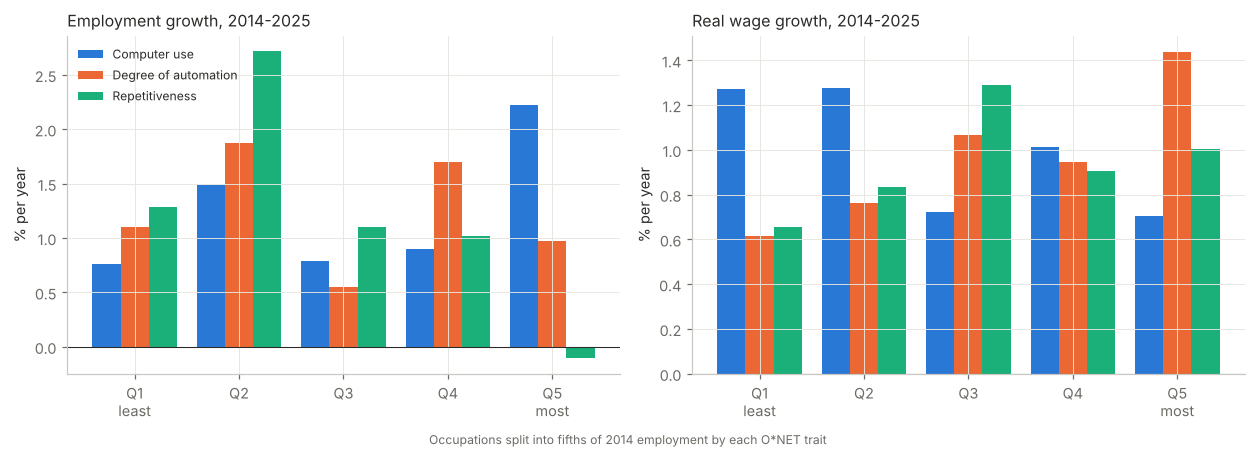

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
x = np.arange(5); wdt = 0.27
for ax, col, ttl in [(axes[0], "emp_growth_pct_yr", f"Employment growth, 2014-{END}"), (axes[1], "real_wage_growth_pct_yr", f"Real wage growth, 2014-{END}")]:
    for i, (t, lab) in enumerate([(q_comp, "Computer use"), (q_auto, "Degree of automation"), (q_rep, "Repetitiveness")]):
        ax.bar(x + (i - 1) * wdt, t[col].values, wdt, color=tc.C[i], label=lab)
    ax.axhline(0, color=tc.INK, lw=0.7); ax.set_xticks(x); ax.set_xticklabels(["Q1\nleast", "Q2", "Q3", "Q4", "Q5\nmost"])
    ax.set_ylabel("% per year"); ax.set_title(ttl, loc="left")
axes[0].legend(loc="upper left", fontsize=8)
fig.text(0.5, -0.02, "Occupations split into fifths of 2014 employment by each O*NET trait", ha="center", color=tc.MUTED, fontsize=8)
fig.tight_layout(); tc.save_fig(fig, "h8_fig2_quintiles")

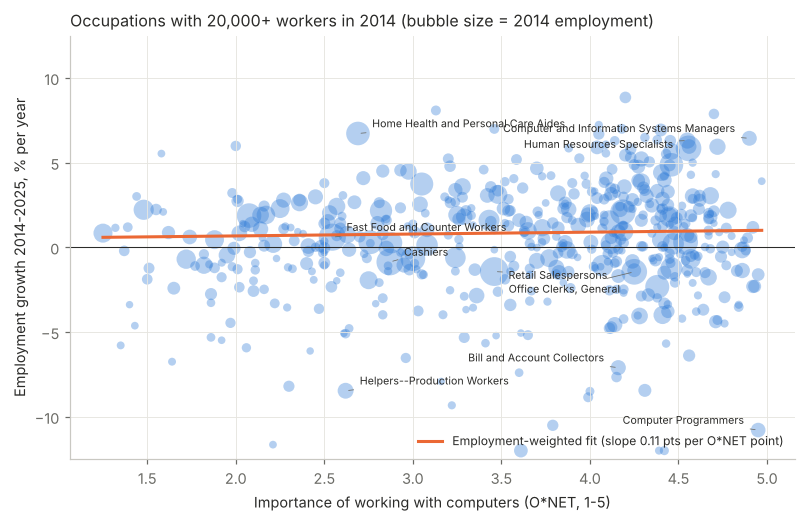

In [9]:
d = reg[reg.emp_2014 >= 20_000]
fig, ax = plt.subplots(figsize=(8.5, 5))
ax.scatter(d.computer, d.g_emp.clip(-12, 12), s=np.sqrt(d.emp_2014) / 6, color=tc.C[0], alpha=0.35, lw=0)
b = np.polyfit(d.computer, d.g_emp, 1, w=np.sqrt(d.emp_2014)); xs = np.linspace(d.computer.min(), d.computer.max(), 50)
ax.plot(xs, np.polyval(b, xs), color=tc.C[1], lw=2, label=f"Employment-weighted fit (slope {b[0]:.2f} pts per O*NET point)")
lab = pd.concat([d.nlargest(4, "emp_2014"), d[d.emp_2014 > 300_000].nsmallest(3, "g_emp"), d[d.emp_2014 > 300_000].nlargest(3, "g_emp")]).drop_duplicates()
placed = []
for _, r in lab.sort_values("g_emp", ascending=False).iterrows():
    x0, y0 = r.computer, float(np.clip(r.g_emp, -12, 12)); ty = y0 + 0.6
    while any(abs(ty - py) < 0.75 and abs(x0 - px) < 1.6 for px, py in placed):
        ty -= 0.8
    placed.append((x0, ty))
    right = x0 > 3.6
    ax.annotate(r.title.replace(" (and related)", "")[:44], (x0, y0), xytext=(x0 + (-0.08 if right else 0.08), ty),
                fontsize=7, color=tc.INK, ha="right" if right else "left", va="center",
                arrowprops=dict(arrowstyle="-", color=tc.MUTED, lw=0.5))
ax.axhline(0, color=tc.INK, lw=0.7); ax.set_ylim(-12.5, 12.5)
ax.set_xlabel("Importance of working with computers (O*NET, 1-5)"); ax.set_ylabel(f"Employment growth 2014-{END}, % per year")
ax.set_title("Occupations with 20,000+ workers in 2014 (bubble size = 2014 employment)", loc="left"); ax.legend(loc="lower right", fontsize=8)
tc.save_fig(fig, "h8_fig3_scatter")

## H8c · Before and after ChatGPT: AI exposure

AIOE scores how much an occupation's abilities overlap with what AI applications can do (image recognition, language modelling, translation and others). It is a measure of exposure, not of harm: exposure can mean help (complement) or replacement (substitute). Thiel's view predicts exposed jobs keep growing after 2022.

In [10]:
AI = {}
if "z_aioe" in both:
    a = both.dropna(subset=["z_aioe", "wage_2014", "wage_2022", f"wage_{END}"]).copy()
    a = a[a.emp_2022 > 0]
    for base, end, tag in [(2014, 2022, "pre"), (2022, END, "post")]:
        n = end - base
        a[f"g_emp_{tag}"] = 100 * np.log(a[f"emp_{end}"] / a[f"emp_{base}"]) / n
        a[f"g_wage_{tag}"] = 100 * (np.log(a[f"wage_{end}"] / a[f"wage_{base}"]) - np.log(defl(end) / defl(base))) / n
    q_pre = quint_table(a, "aioe", 2014, 2022, "h8c_quintiles_aioe_2014_2022")
    q_post = quint_table(a.assign(emp_2014=a.emp_2022), "aioe", 2022, END, f"h8c_quintiles_aioe_2022_{END}")
    RA = []
    for tag in ["pre", "post"]:
        for y in ["g_emp", "g_wage"]:
            a["z_lw"] = wz(np.log(a[f"wage_{2014 if tag == 'pre' else 2022}"]), a.emp_2014 if tag == "pre" else a.emp_2022)
            for spec in (["z_aioe"], ["z_aioe", "z_computer"], ["z_aioe", "z_computer", "z_lw"]):
                d_ = a.dropna(subset=spec)
                r = tc.wls(d_[f"{y}_{tag}"], d_[spec].values, d_.emp_2014 if tag == "pre" else d_.emp_2022, spec)
                RA.append(r[r.x != "const"].assign(y=y, period=tag, spec=" + ".join(spec)))
    RA = pd.concat(RA, ignore_index=True); tc.save_table(RA, "h8c_regressions", index=False)
    top_ai = a[a.emp_2022 >= 100_000].nlargest(12, "aioe")[["title", "aioe", "emp_2014", "emp_2022", f"emp_{END}", "g_emp_pre", "g_emp_post", "g_wage_pre", "g_wage_post"]]
    tc.save_table(top_ai.round(2), "h8c_most_exposed", index=False)
    AI = {"n": int(len(a)), "quintiles_pre": json.loads(q_pre.round(3).to_json(orient="index")),
          "quintiles_post": json.loads(q_post.round(3).to_json(orient="index")),
          "regressions": json.loads(RA.round(4).to_json(orient="records")),
          "most_exposed": json.loads(top_ai.round(2).to_json(orient="records"))}
    print("2014-2022:"); display(q_pre.round(2)); print(f"2022-{END}:"); display(q_post.round(2)); display(RA.round(3)); display(top_ai.round(2))
else:
    print("AI exposure scores not available; H8c skipped.")

2014-2022:


,mean_aioe,occupations,emp_2014_m,emp_2022_m,emp_growth_pct_yr,real_wage_growth_pct_yr
Q1 (least),-1.36,160.0,25.41,27.01,0.76,0.78
Q2,-0.71,144.0,26.51,29.30,1.25,0.80
Q3,-0.05,122.0,25.97,26.58,0.29,1.01
Q4,0.82,140.0,26.23,28.76,1.15,0.43
Q5 (most),1.26,163.0,26.26,31.02,2.09,0.36


2022-2025:


,mean_aioe,occupations,emp_2022_m,emp_2025_m,emp_growth_pct_yr,real_wage_growth_pct_yr
Q1 (least),-1.36,160.0,27.01,27.56,0.66,1.68
Q2,-0.71,144.0,29.30,31.49,2.41,2.02
Q3,-0.02,150.0,29.25,31.18,2.13,1.84
Q4,0.87,117.0,28.46,28.57,0.13,1.94
Q5 (most),1.28,158.0,28.66,31.06,2.68,1.23


,x,coef,se,p,n,r2,y,period,spec
0,z_aioe,0.236,0.255,0.355,729,0.006,g_emp,pre,z_aioe
1,z_aioe,-0.112,0.312,0.719,722,0.010,g_emp,pre,z_aioe + z_computer
2,z_computer,0.401,0.323,0.214,722,0.010,g_emp,pre,z_aioe + z_computer
3,z_aioe,-0.470,0.289,0.104,722,0.130,g_emp,pre,z_aioe + z_computer + z_lw
4,z_computer,-0.150,0.274,0.585,722,0.130,g_emp,pre,z_aioe + z_computer + z_lw
5,z_lw,1.405,0.303,0.000,722,0.130,g_emp,pre,z_aioe + z_computer + z_lw
6,z_aioe,-0.521,0.065,0.000,729,0.230,g_wage,pre,z_aioe
7,z_aioe,-0.094,0.101,0.354,722,0.311,g_wage,pre,z_aioe + z_computer
8,z_computer,-0.525,0.110,0.000,722,0.311,g_wage,pre,z_aioe + z_computer
9,z_aioe,0.067,0.074,0.363,722,0.522,g_wage,pre,z_aioe + z_computer + z_lw


,title,aioe,emp_2014,emp_2022,emp_2025,g_emp_pre,g_emp_post,g_wage_pre,g_wage_post
g,,,,,,,,,
B13-2011,Accountants and Auditors,1.48,1187310.0,1402420.0,1449500.0,2.08,1.10,-0.61,0.63
B11-9033,"Education Administrators, Postsecondary",1.46,131070.0,167060.0,180470.0,3.03,2.57,-1.12,0.82
B19-3034,Clinical and Counseling Psychologists (and rel...,1.46,104730.0,123130.0,139930.0,2.02,4.26,0.51,1.40
B11-3031,Financial Managers,1.45,518030.0,740780.0,841710.0,4.47,4.26,0.39,1.63
B13-1111,Management Analysts,1.43,587450.0,808860.0,898280.0,4.00,3.50,-0.88,0.47
B13-1161,Market Research Analysts and Marketing Special...,1.43,468160.0,798620.0,899580.0,6.68,3.97,-0.92,1.89
B13-2052,Personal Financial Advisors,1.40,196490.0,283060.0,266800.0,4.56,-1.97,0.38,1.97
B15-2031,Operations Research Analysts,1.40,86950.0,105080.0,108510.0,2.37,1.07,-0.85,-0.98
B13-2072,Loan Officers,1.39,300580.0,345550.0,274330.0,1.74,-7.69,-0.99,-0.91


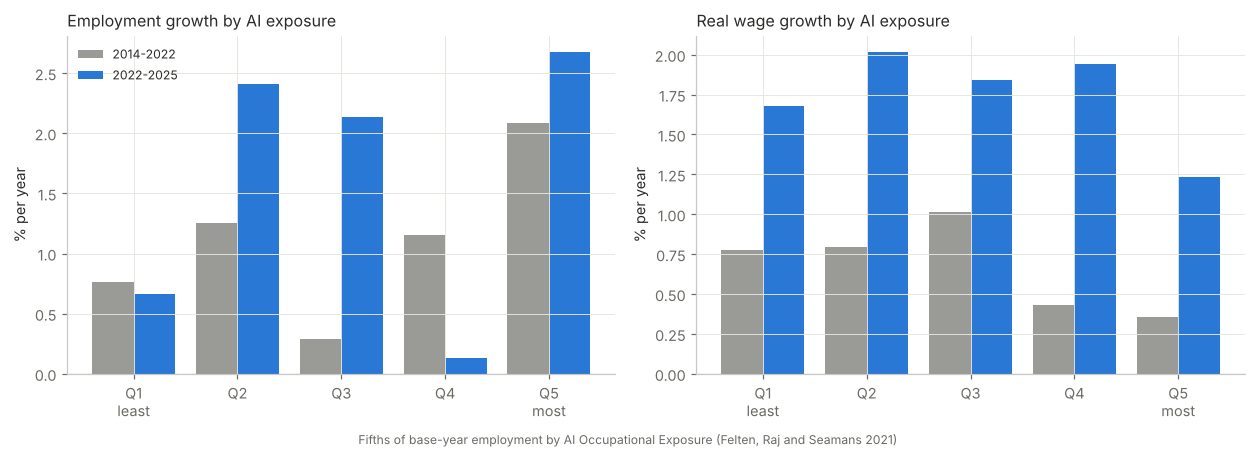

In [11]:
if AI:
    fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
    x = np.arange(5)
    for ax, col, ttl in [(axes[0], "emp_growth_pct_yr", "Employment growth"), (axes[1], "real_wage_growth_pct_yr", "Real wage growth")]:
        ax.bar(x - 0.2, q_pre[col].values, 0.4, color=tc.GREY, label="2014-2022")
        ax.bar(x + 0.2, q_post[col].values, 0.4, color=tc.C[0], label=f"2022-{END}")
        ax.axhline(0, color=tc.INK, lw=0.7); ax.set_xticks(x); ax.set_xticklabels(["Q1\nleast", "Q2", "Q3", "Q4", "Q5\nmost"])
        ax.set_ylabel("% per year"); ax.set_title(f"{ttl} by AI exposure", loc="left")
    axes[0].legend(loc="upper left", fontsize=8)
    fig.text(0.5, -0.02, "Fifths of base-year employment by AI Occupational Exposure (Felten, Raj and Seamans 2021)", ha="center", color=tc.MUTED, fontsize=8)
    fig.tight_layout(); tc.save_fig(fig, "h8_fig4_ai")

## Verdict inputs and check cell — send me this output

In [12]:
rec = lambda df: json.loads(df.round(4).to_json(orient="records"))
summary = {
    "end_year": END, "last_aggregate_year": LAST,
    "aggregate_periods": json.loads(agg.to_json(orient="columns")),
    "employment_levels": json.loads(levels.to_json(orient="index")),
    "coverage": cov,
    "quintiles_computer": json.loads(q_comp.round(3).to_json(orient="index")),
    "quintiles_automation": json.loads(q_auto.round(3).to_json(orient="index")),
    "quintiles_repetitive": json.loads(q_rep.round(3).to_json(orient="index")),
    "quintiles_pay": json.loads(q_pay.round(3).to_json(orient="index")),
    "corr_computer_logpay": round(float(np.corrcoef(reg.computer, np.log(reg.wage_2014))[0, 1]), 3),
    "regressions": rec(R),
    "movers": json.loads(movers.round(2).to_json(orient="records")),
    "aggregate_emp_growth_pct_yr": round(100 * np.log(ok[f"emp_{END}"].sum() / ok.emp_2014.sum()) / yrs, 3),
    "ai": AI,
}
(tc.OUT / "h8_summary.json").write_text(json.dumps(summary, indent=1, default=str))
print(json.dumps(summary, indent=1, default=str)[:6000])

{
 "end_year": 2025,
 "last_aggregate_year": 2024,
 "aggregate_periods": {
  "1979-1995": {
   "Labour productivity, % per year": 1.5,
   "Real median weekly earnings, % per year": -0.33,
   "Labour share, change in points": -3.61,
   "Prime-age employment rate at end, %": 79.74
  },
  "1995-2004": {
   "Labour productivity, % per year": 3.04,
   "Real median weekly earnings, % per year": 0.79,
   "Labour share, change in points": -0.83,
   "Prime-age employment rate at end, %": 78.97
  },
  "2004-2014": {
   "Labour productivity, % per year": 1.56,
   "Real median weekly earnings, % per year": -0.1,
   "Labour share, change in points": -7.68,
   "Prime-age employment rate at end, %": 76.7
  },
  "2014-2024": {
   "Labour productivity, % per year": 1.79,
   "Real median weekly earnings, % per year": 1.0,
   "Labour share, change in points": -2.27,
   "Prime-age employment rate at end, %": 80.72
  }
 },
 "employment_levels": {
  "2000": {
   "prime_age_employment_rate": 81.5,
   "unempl